# 1. Setup and Imports

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# Import our modules
import utils
from graph_builder import PollutionGraph
from pathfinding import AStarAlgorithm, DijkstraAlgorithm, BFSAlgorithm
from visualization import BucharestMapVisualizer

print("All imports successful!")

All imports successful!


# 2. Mock data

In [2]:
print("Creating mock pollution data...\n")

# Define pollution hotspots in Bucharest
mock_pollution_data = [
    # High pollution areas (major traffic zones)
    {'lat': 44.4268, 'lon': 26.1025, 'pm10': 65.0, 'pm25': 35.0, 'no2': 55.0},  # Center
    {'lat': 44.4478, 'lon': 26.0975, 'pm10': 70.0, 'pm25': 40.0, 'no2': 60.0},  # North
    {'lat': 44.4100, 'lon': 26.1200, 'pm10': 68.0, 'pm25': 38.0, 'no2': 58.0},  # East
    
    # Medium pollution areas
    {'lat': 44.4350, 'lon': 26.0800, 'pm10': 45.0, 'pm25': 25.0, 'no2': 35.0},  # West
    {'lat': 44.4150, 'lon': 26.1000, 'pm10': 50.0, 'pm25': 28.0, 'no2': 40.0},  # South-Center
    {'lat': 44.4400, 'lon': 26.1300, 'pm10': 48.0, 'pm25': 27.0, 'no2': 38.0},  # East-Center
    
    # Low pollution areas (parks, suburbs)
    {'lat': 44.4650, 'lon': 26.0850, 'pm10': 25.0, 'pm25': 12.0, 'no2': 18.0},  # Herastrau Park
    {'lat': 44.4000, 'lon': 26.0900, 'pm10': 30.0, 'pm25': 15.0, 'no2': 20.0},  # South
    {'lat': 44.4500, 'lon': 26.0650, 'pm10': 28.0, 'pm25': 14.0, 'no2': 19.0},  # West suburbs
    {'lat': 44.4200, 'lon': 26.1500, 'pm10': 32.0, 'pm25': 16.0, 'no2': 22.0},  # East suburbs
]

# Display pollution data
df_pollution = pd.DataFrame(mock_pollution_data)
print("Mock Pollution Data:")
print(df_pollution.to_string(index=False))
print(f"\nTotal data points: {len(mock_pollution_data)}")
print(f"PM10 range: {df_pollution['pm10'].min():.1f} - {df_pollution['pm10'].max():.1f} µg/m³")
print(f"PM2.5 range: {df_pollution['pm25'].min():.1f} - {df_pollution['pm25'].max():.1f} µg/m³")
print(f"NO2 range: {df_pollution['no2'].min():.1f} - {df_pollution['no2'].max():.1f} µg/m³")

Creating mock pollution data...

Mock Pollution Data:
    lat     lon  pm10  pm25  no2
44.4268 26.1025  65.0  35.0 55.0
44.4478 26.0975  70.0  40.0 60.0
44.4100 26.1200  68.0  38.0 58.0
44.4350 26.0800  45.0  25.0 35.0
44.4150 26.1000  50.0  28.0 40.0
44.4400 26.1300  48.0  27.0 38.0
44.4650 26.0850  25.0  12.0 18.0
44.4000 26.0900  30.0  15.0 20.0
44.4500 26.0650  28.0  14.0 19.0
44.4200 26.1500  32.0  16.0 22.0

Total data points: 10
PM10 range: 25.0 - 70.0 µg/m³
PM2.5 range: 12.0 - 40.0 µg/m³
NO2 range: 18.0 - 60.0 µg/m³


# 3. Build Pollution Graph

In [3]:
# Use larger resolution for faster testing (0.005 ≈ 500m)
# For production use 0.001 (≈ 100m)
resolution = 0.005
alpha = 0.7  # 70% pollution weight, 30% distance weight

print(f"Resolution: {resolution} degrees (~{resolution * 111:.0f}m)")
print(f"Alpha (pollution weight): {alpha}")
print(f"Beta (distance weight): {1-alpha}\n")

graph = PollutionGraph(resolution=resolution)
graph.build_from_pollution_data(mock_pollution_data)

print(f"\nGraph built successfully!")
print(f"  Total nodes: {len(graph.nodes)}")
print(f"  Bounding box: lat {graph.bbox['lat_min']:.3f}-{graph.bbox['lat_max']:.3f}, lon {graph.bbox['lon_min']:.3f}-{graph.bbox['lon_max']:.3f}")
print(f"  Grid dimensions: {int((graph.bbox['lat_max'] - graph.bbox['lat_min']) / resolution)} x {int((graph.bbox['lon_max'] - graph.bbox['lon_min']) / resolution)}")

Resolution: 0.005 degrees (~1m)
Alpha (pollution weight): 0.7
Beta (distance weight): 0.30000000000000004

Building graph with resolution 0.005...
Grid dimensions: 30 x 50
Populated 10 cells with real data
Interpolating missing values...
Interpolated 1460 cells
Building edges...
Graph ready: 1470 nodes, 11290 edges

Graph built successfully!
  Total nodes: 1470
  Bounding box: lat 44.350-44.500, lon 25.950-26.200
  Grid dimensions: 29 x 50


# 4. Define start and goal

In [4]:
# Example: From North (Herastrau area) to South-East (Titan area)
start_lat, start_lon = 44.465, 26.085  # Near Herastrau Park (low pollution)
goal_lat, goal_lon = 44.410, 26.150    # Near Titan area (medium pollution)

# Convert to grid cells
start = utils.get_grid_cell(start_lat, start_lon, resolution)
goal = utils.get_grid_cell(goal_lat, goal_lon, resolution)

print(f"Start: ({start_lat}, {start_lon}) → Cell {start}")
print(f"Goal:  ({goal_lat}, {goal_lon}) → Cell {goal}\n")

# Verify cells are in graph
if start in graph.nodes:
    start_node = graph.nodes[start]
    print(f"Start node found")
    print(f"Pollution: PM10={start_node['pollution']['pm10']:.1f}, PM2.5={start_node['pollution']['pm25']:.1f}, NO2={start_node['pollution']['no2']:.1f}")
else:
    print(f"Start node NOT in graph!")

if goal in graph.nodes:
    goal_node = graph.nodes[goal]
    print(f"Goal node found")
    print(f"Pollution: PM10={goal_node['pollution']['pm10']:.1f}, PM2.5={goal_node['pollution']['pm25']:.1f}, NO2={goal_node['pollution']['no2']:.1f}")
else:
    print(f"Goal node NOT in graph!")

# Calculate straight-line distance
straight_distance = utils.haversine_distance(start_lat, start_lon, goal_lat, goal_lon)
print(f"\nStraight-line distance: {straight_distance:.2f} km")

Start: (44.465, 26.085) → Cell (8893, 5217)
Goal:  (44.41, 26.15) → Cell (8882, 5230)

Start node found
Pollution: PM10=25.0, PM2.5=0.0, NO2=18.0
Goal node found
Pollution: PM10=39.1, PM2.5=0.0, NO2=29.1

Straight-line distance: 8.00 km


# 5. Test a* with heuristics

In [ ]:
heuristics = [
    ('Haversine', utils.haversine_heuristic),
    ('Euclidean', utils.euclidean_heuristic),
    ('Manhattan', utils.manhattan_heuristic),
]

astar_results = []

for name, heuristic_fn in heuristics:
    print(f"Testing A* with {name} heuristic...")
    
    algo = AStarAlgorithm(graph, heuristic_fn=heuristic_fn)
    result = algo.find_path(start, goal)

    if 'error' not in result:
        stats = algo.get_stats()

        # Calculate actual distance
        path = result['path']
        total_dist = 0
        for i in range(1, len(path)):
            c1_lat = path[i-1][0] * resolution
            c1_lon = path[i-1][1] * resolution
            c2_lat = path[i][0] * resolution
            c2_lon = path[i][1] * resolution
            total_dist += utils.haversine_distance(c1_lat, c1_lon, c2_lat, c2_lon)

        astar_results.append({
            'Heuristic': name,
            'Nodes Explored': stats['nodes_explored'],
            'Path Length': stats['path_length'],
            'Total Cost': stats['total_cost'],
            'Distance (km)': total_dist
        })

        print(f"Nodes explored: {stats['nodes_explored']}")
        print(f"Path length: {stats['path_length']} nodes")
        print(f"Total cost: {stats['total_cost']:.4f}")
        print(f"Distance: {total_dist:.2f} km\n")
    else:
        print(f"Error: {result['error']}\n")

# Display comparison table
if astar_results:
    df_astar = pd.DataFrame(astar_results)
    print("\nA* HEURISTIC COMPARISON:")
    print(df_astar.to_string(index=False))

Testing A* with Haversine heuristic...
Nodes explored: 23
Path length: 14 nodes
Total cost: 7.6936
Distance: 8.31 km

Testing A* with Euclidean heuristic...
Nodes explored: 652
Path length: 14 nodes
Total cost: 7.2076
Distance: 8.31 km

Testing A* with Manhattan heuristic...
Nodes explored: 651
Path length: 14 nodes
Total cost: 7.2076
Distance: 8.31 km


A* HEURISTIC COMPARISON:
Heuristic  Nodes Explored  Path Length  Total Cost  Distance (km)
Haversine              23           14    7.693647       8.308650
Euclidean             652           14    7.207589       8.308242
Manhattan             651           14    7.207589       8.308242


# 6. Test Dijkstra

In [6]:
dijkstra = DijkstraAlgorithm(graph)
result_dijkstra = dijkstra.find_path(start, goal)

if 'error' not in result_dijkstra:
    stats = dijkstra.get_stats()
    
    # Calculate distance
    path = result_dijkstra['path']
    total_dist = 0
    for i in range(1, len(path)):
        c1_lat = path[i-1][0] * resolution
        c1_lon = path[i-1][1] * resolution
        c2_lat = path[i][0] * resolution
        c2_lon = path[i][1] * resolution
        total_dist += utils.haversine_distance(c1_lat, c1_lon, c2_lat, c2_lon)
    
    print(f"Nodes explored: {stats['nodes_explored']}")
    print(f"Path length: {stats['path_length']} nodes")
    print(f"Total cost: {stats['total_cost']:.4f}")
    print(f"Distance: {total_dist:.2f} km")
else:
    print(f"Error: {result_dijkstra['error']}")

Nodes explored: 855
Path length: 14 nodes
Total cost: 7.2076
Distance: 8.31 km


# 7. Test BFS

In [7]:
bfs = BFSAlgorithm(graph)
result_bfs = bfs.find_path(start, goal)

if 'error' not in result_bfs:
    stats = bfs.get_stats()

    # Calculate distance
    path = result_bfs['path']
    total_dist = 0
    for i in range(1, len(path)):
        c1_lat = path[i-1][0] * resolution
        c1_lon = path[i-1][1] * resolution
        c2_lat = path[i][0] * resolution
        c2_lon = path[i][1] * resolution
        total_dist += utils.haversine_distance(c1_lat, c1_lon, c2_lat, c2_lon)
    
    print(f"Nodes explored: {stats['nodes_explored']}")
    print(f"Path length: {stats['path_length']} nodes")
    print(f"Distance: {total_dist:.2f} km")
    print("(BFS does not consider costs)")
else:
    print(f"Error: {result_bfs['error']}")

TypeError: 'NoneType' object is not subscriptable

# 8: Comparison Table

In [8]:
comparison_data = []

# A* (best heuristic - Haversine)
astar_best = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)
result_astar = astar_best.find_path(start, goal)
if 'error' not in result_astar:
    stats = astar_best.get_stats()
    path = result_astar['path']
    dist = sum([utils.haversine_distance(
        path[i-1][0]*resolution, path[i-1][1]*resolution,
        path[i][0]*resolution, path[i][1]*resolution
    ) for i in range(1, len(path))])
    
    comparison_data.append({
        'Algorithm': 'A* (Haversine)',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': f"{stats['total_cost']:.4f}",
        'Distance (km)': f"{dist:.2f}"
    })

# Dijkstra
if 'error' not in result_dijkstra:
    stats = dijkstra.get_stats()
    path = result_dijkstra['path']
    dist = sum([utils.haversine_distance(
        path[i-1][0]*resolution, path[i-1][1]*resolution,
        path[i][0]*resolution, path[i][1]*resolution
    ) for i in range(1, len(path))])
    
    comparison_data.append({
        'Algorithm': 'Dijkstra',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': f"{stats['total_cost']:.4f}",
        'Distance (km)': f"{dist:.2f}"
    })

# BFS
if 'error' not in result_bfs:
    stats = bfs.get_stats()
    path = result_bfs['path']
    dist = sum([utils.haversine_distance(
        path[i-1][0]*resolution, path[i-1][1]*resolution,
        path[i][0]*resolution, path[i][1]*resolution
    ) for i in range(1, len(path))])
    
    comparison_data.append({
        'Algorithm': 'BFS',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': 'N/A',
        'Distance (km)': f"{dist:.2f}"
    })

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison.to_string(index=False))
print("\nKey Insights:")
print("- A* explores fewer nodes than Dijkstra (heuristic guidance)")
print("- Dijkstra guarantees optimal path but explores more nodes")
print("- BFS finds a path but ignores pollution costs")

TypeError: 'NoneType' object is not subscriptable

# 9: Visualization Setup

In [9]:
# Check for map image
map_path = '../images/bucharest_base.png'

if os.path.exists(map_path):
    print(f"Found map image: {map_path}")
    map_available = True
else:
    print(f"No map image found at {map_path}")
    print("Visualization will use plain background with pollution overlay")
    print("To add map: save a Bucharest map screenshot as 'images/bucharest_base.png'")
    map_path = None
    map_available = False

# Create visualizer
viz = BucharestMapVisualizer(graph, map_image_path=map_path)
print("\nMap visualizer ready!")

Found map image: ../images/bucharest_base.png
Loaded map image: ../images/bucharest_base.png

✓ Map visualizer ready!


# 10. Visualize A*

 Saved: ../images/astar_on_bucharest.png


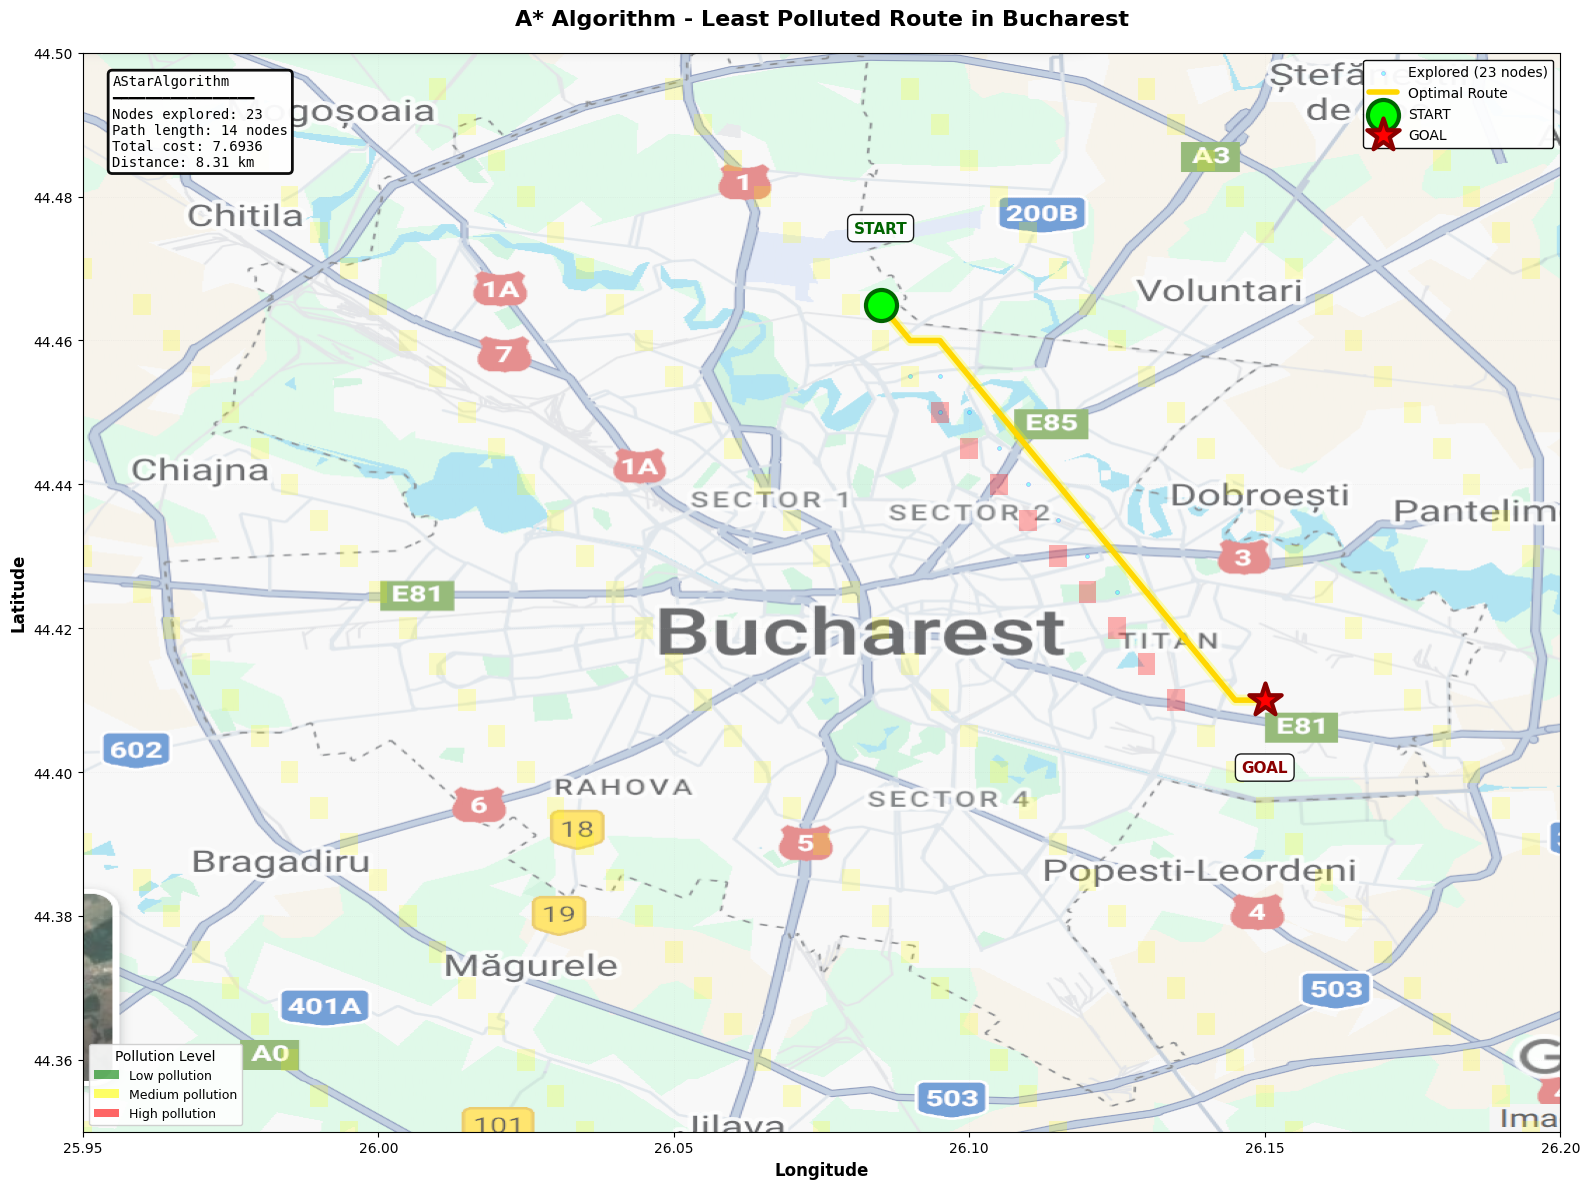


Visualization complete!


In [14]:
# Create fresh A* instance
astar_viz = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)

# Plot on map
viz.plot_algorithm_on_map(
    astar_viz,
    start,
    goal,
    title="A* Algorithm - Least Polluted Route in Bucharest",
    output_file='astar_on_bucharest.png',
    show=True
)

print("\nVisualization complete!")

# 11: Compare All Algorithms (2)

Processing AStarAlgorithm...
Processing DijkstraAlgorithm...
Processing BFSAlgorithm...


TypeError: 'NoneType' object is not subscriptable

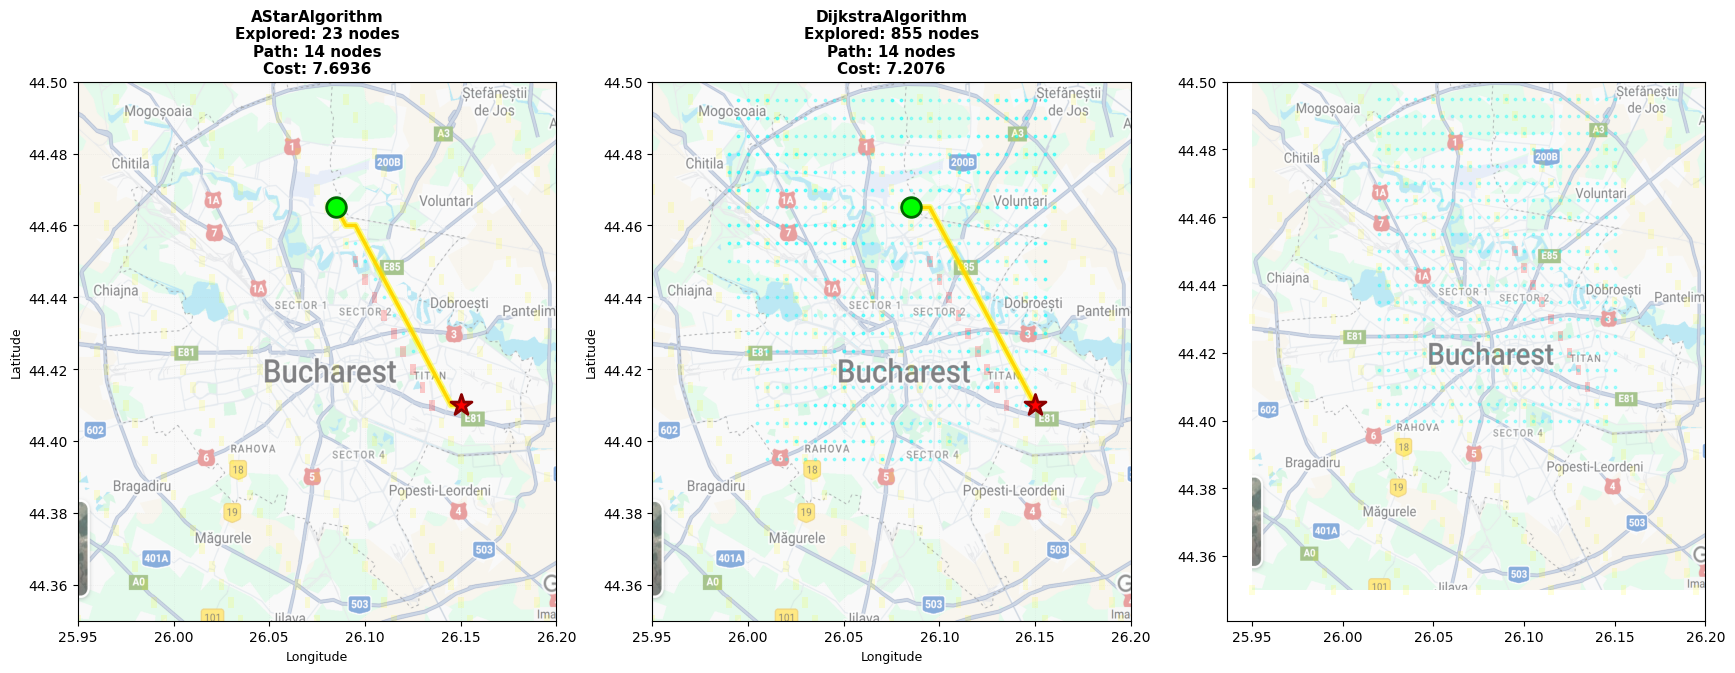

In [11]:
# Create fresh instances for comparison
algorithms_for_viz = [
    AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic),
    DijkstraAlgorithm(graph),
    BFSAlgorithm(graph)
]

# Compare on separate subplots
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for idx, algo in enumerate(algorithms_for_viz):
    ax = axes[idx]
    
    print(f"Processing {algo.__class__.__name__}...")
    result = algo.find_path(start, goal)
    
    if 'error' in result:
        ax.text(0.5, 0.5, f'{algo.__class__.__name__}\nFAILED', 
               ha='center', va='center', fontsize=14, transform=ax.transAxes)
        continue
    
    # Draw base map if available
    if viz.map_image is not None:
        ax.imshow(viz.map_image, extent=[
            viz.bbox['lon_min'], viz.bbox['lon_max'],
            viz.bbox['lat_min'], viz.bbox['lat_max']
        ], aspect='auto', alpha=0.6, zorder=0)
    else:
        ax.set_facecolor('#e8e8e8')
    
    # Draw pollution overlay
    viz._draw_pollution_overlay(ax, alpha=0.2)
    
    # Draw exploration
    visited = result['visited_nodes']
    if visited:
        v_coords = [viz._cell_to_coords(v['cell']) for v in visited]
        v_lat = [c[0] for c in v_coords]
        v_lon = [c[1] for c in v_coords]
        ax.scatter(v_lon, v_lat, c='cyan', s=3, alpha=0.3, zorder=3)
    
    # Draw path
    path = result['path']
    if path:
        p_coords = [viz._cell_to_coords(c) for c in path]
        p_lat = [c[0] for c in p_coords]
        p_lon = [c[1] for c in p_coords]
        ax.plot(p_lon, p_lat, 'yellow', linewidth=5, alpha=0.5, zorder=4)
        ax.plot(p_lon, p_lat, 'gold', linewidth=2.5, zorder=5)
    
    # Start and goal markers
    start_coords = viz._cell_to_coords(start)
    goal_coords = viz._cell_to_coords(goal)
    ax.scatter([start_coords[1]], [start_coords[0]], c='lime', s=200, 
              marker='o', zorder=6, edgecolors='darkgreen', linewidths=2)
    ax.scatter([goal_coords[1]], [goal_coords[0]], c='red', s=250,
              marker='*', zorder=6, edgecolors='darkred', linewidths=2)
    
    # Stats in title
    stats = algo.get_stats()
    title = f"{algo.__class__.__name__}\n"
    title += f"Explored: {stats['nodes_explored']} nodes\n"
    title += f"Path: {stats['path_length']} nodes"
    if 'total_cost' in stats:
        title += f"\nCost: {stats['total_cost']:.4f}"
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=9)
    ax.set_ylabel('Latitude', fontsize=9)
    ax.set_xlim(viz.bbox['lon_min'], viz.bbox['lon_max'])
    ax.set_ylim(viz.bbox['lat_min'], viz.bbox['lat_max'])
    ax.grid(True, alpha=0.2, linestyle=':', linewidth=0.5)

plt.suptitle('Algorithm Comparison on Bucharest Map', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

save_path = '../images/algorithm_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"\nSaved comparison: {save_path}")

plt.show()
print("\nComparison complete!")

# 12. Animation

In [13]:
# Check if ffmpeg is available
import subprocess

try:
    subprocess.run(['ffmpeg', '-version'], capture_output=True, check=True)
    ffmpeg_available = True
    print("ffmpeg is available")
except (subprocess.CalledProcessError, FileNotFoundError):
    ffmpeg_available = False
    print("ffmpeg not found - skipping animation")
    print("To enable: sudo apt-get install ffmpeg")

if ffmpeg_available:
    print("Creating animation")
    print("This may take 1-2 minutes...\n")
    
    # Create fresh algorithm instance
    astar_anim = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)
    
    try:
        viz.animate_algorithm(
            astar_anim,
            start,
            goal,
            output_file='astar_exploration.mp4',
            interval=30,
            show_cost=True
        )
        print("\nAnimation complete!")
    except Exception as e:
        print(f"\nAnimation failed: {e}")
else:
    print("\nSkipping animation (ffmpeg not available)")

ffmpeg is available
Creating animation
This may take 1-2 minutes...

Running AStarAlgorithm...
Creating animation with 23 frames...
Rendering animation...
 Animation saved: ../images/astar_exploration.mp4

Animation complete!
